# Данные, доступный каталог и метрики

Проверяем, какие события и товары были доступны до прогноза. На основной неделе у 4 319 пользователей был хотя бы один будущий клик по товару из каталога.

[Описание главы](README.md)

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Импорт работает и без editable install, если notebook открыт внутри репозитория.
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'research').is_dir())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.presentation import setup_style, save_figure
from recsys_lab.statistics import paired_bootstrap
from recsys_lab.session import ResearchSession
import os
setup_style()

chapter = root / 'research/01_data_and_protocol'
results = chapter / 'results'
figures = chapter / 'figures'

# saved: результаты первоначального исследования; train: новый рабочий запуск.
MODE = "saved"
RUN_NAME = "reproduction"
RAW_DIR = os.environ.get("T_ECD_RAW")  # Каталог с items.pq и events/.
session = ResearchSession(mode=MODE, run_name=RUN_NAME, raw_dir=RAW_DIR)

def read(name):
    return session.read(chapter.name, name)

registry = pd.read_csv(root / 'results/experiment_registry.csv')

## Запуск этапа

`saved` показывает результаты прежних опытов. Для `train` задайте каталог данных и выполняйте главы по порядку.

In [2]:
# В saved обучение не вызывается. В train выполняется соответствующий этап.
session.run("01_data_and_protocol")
result_table = session.metrics("01_data_and_protocol")
display(result_table)

Используем сохранённые результаты.


,rows,null_users,missing_items,null_time,invalid_actions,day_time_mismatch,missing_surface
0,19799501,0,0,0,0,0,10150


## Результаты подготовки

## Размеры и временные границы

Когорта выбрана по прошлой активности. Размеры среза и временные границы заданы в конфигурации.

In [3]:
protocol = json.loads((root / 'configs/protocol.json').read_text())
display(pd.Series(protocol, name='значение').to_frame())
daily = read('data_quality_20261104__daily_events.csv')
quality = read('data_quality_20261104__processed_quality.csv')
display(quality)
assert int(quality.rows.iloc[0]) == 19_799_501
assert quality[['null_users','missing_items','null_time','invalid_actions','day_time_mismatch']].to_numpy().sum() == 0

,значение
dataset,T-ECD Small Marketplace
revision,79bcf78cd4699267f561ad3fd51fe7b52af53083
cohort,80018
cohort_days,"[1202, 1261]"
dev_anchors,"[1279, 1286, 1293]"
query_history_days,60
query_length_initial,50
query_length_later,100
gap_days,1
target,unique_click_items


,rows,null_users,missing_items,null_time,invalid_actions,day_time_mismatch,missing_surface
0,19799501,0,0,0,0,0,10150


## События по дням

Сравниваем число событий и кликов выбранной когорты. Изменение объёма само по себе не доказывает потерю данных.

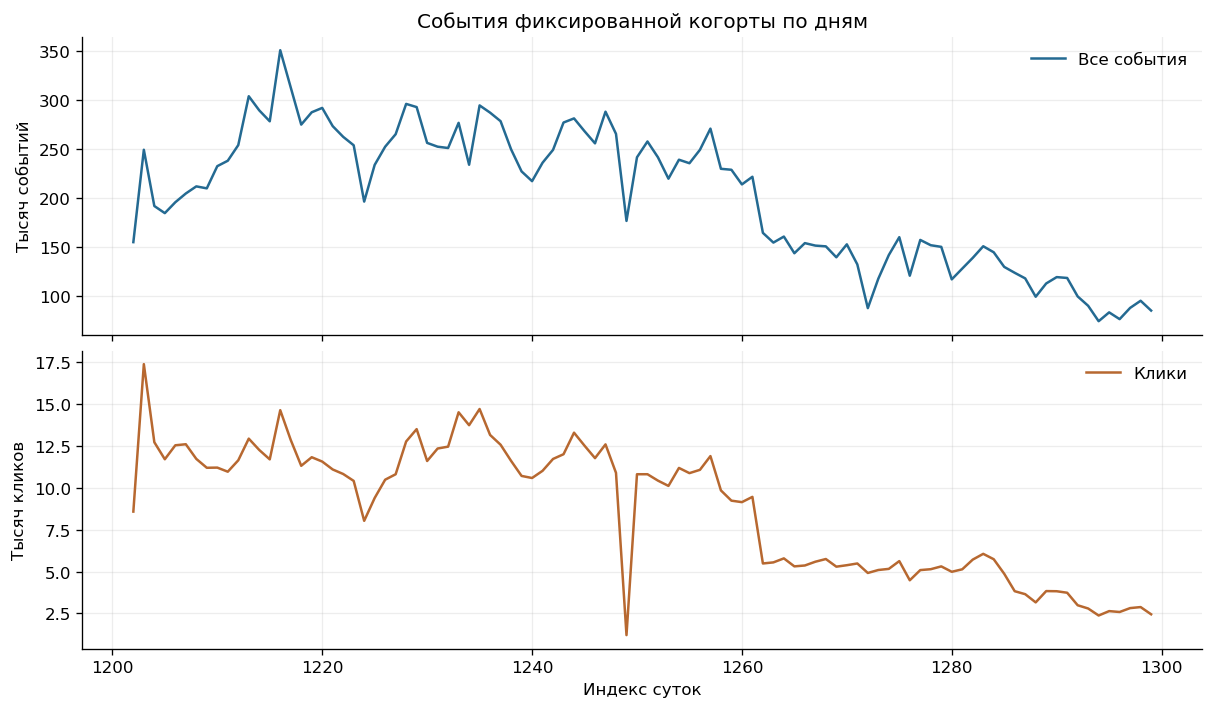

In [4]:
daily = read('data_quality_20261104__daily_events.csv')
fig, axes = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True)
axes[0].plot(daily.day, daily.events / 1000, color='#246A92', label='Все события')
axes[0].set(ylabel='Тысяч событий', title='События фиксированной когорты по дням')
axes[1].plot(daily.day, daily.clicks / 1000, color='#B76830', label='Клики')
axes[1].set(xlabel='Индекс суток', ylabel='Тысяч кликов')
for ax in axes:
    ax.legend(frameon=False)
save_figure(fig, figures / 'daily_events.png')
plt.show()

## Границы суток

Для каждого дня сравниваем время первого и последнего событий с полуночью.

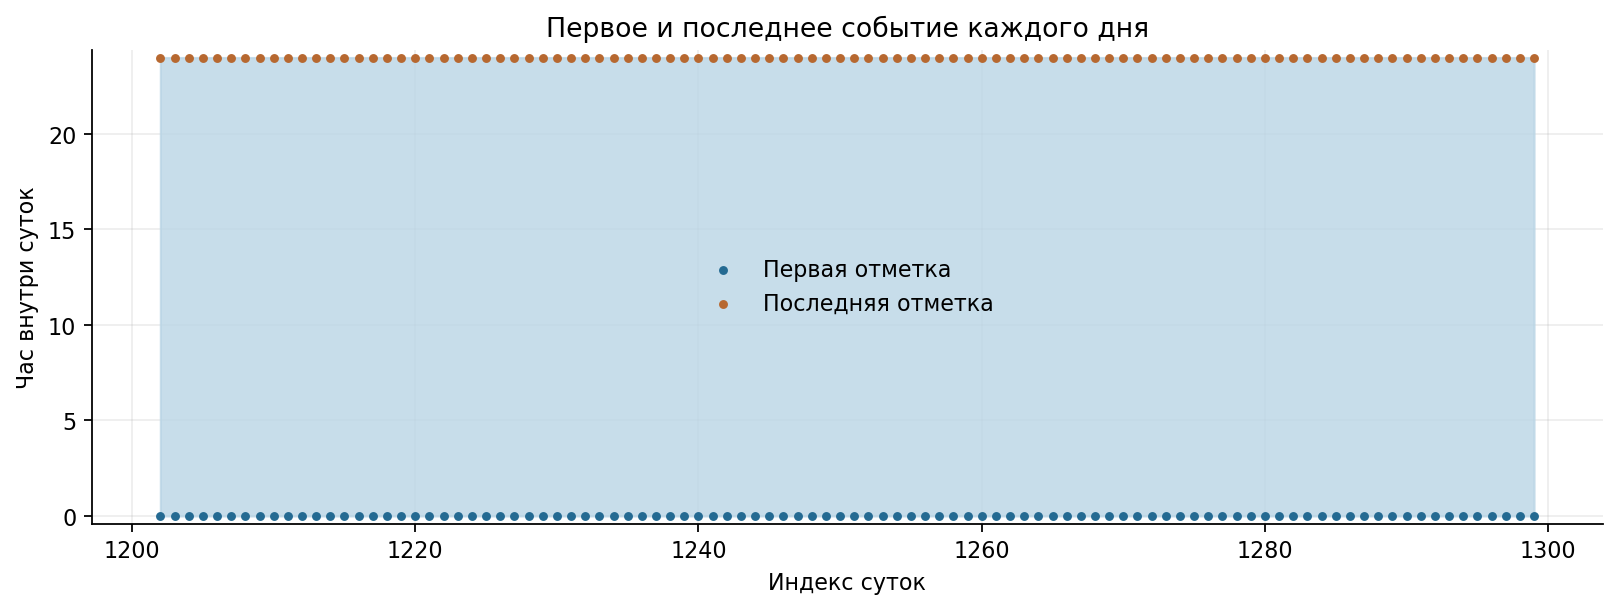

In [5]:
daily = read('data_quality_20261104__daily_events.csv')
day_us = 86_400_000_000
first_hours = (daily.first_ts - daily.day * day_us) / 3_600_000_000
last_hours = (daily.last_ts - daily.day * day_us) / 3_600_000_000
fig, ax = plt.subplots(figsize=(10, 3.7))
ax.fill_between(daily.day, first_hours, last_hours, color='#BAD5E5', alpha=.8)
ax.scatter(daily.day, first_hours, s=9, color='#246A92', label='Первая отметка')
ax.scatter(daily.day, last_hours, s=9, color='#B76830', label='Последняя отметка')
ax.set(xlabel='Индекс суток', ylabel='Час внутри суток', ylim=(-.4,24.4), title='Первое и последнее событие каждого дня')
ax.legend(frameon=False, loc='center')
save_figure(fig, figures / 'day_coverage.png')
plt.show()

In [6]:
coverage = daily[['day','events','clicks']].copy()
coverage['first_hour'] = first_hours
coverage['last_hour'] = last_hours
display(coverage[(coverage.first_hour > 1) | (coverage.last_hour < 23)])
display(coverage.tail(7))

,day,events,clicks,first_hour,last_hour


,day,events,clicks,first_hour,last_hour
91,1293,89845,2794,0.000088,23.999973
92,1294,74092,2375,0.000692,23.999753
93,1295,83116,2638,0.000017,23.999929
94,1296,76199,2585,0.000043,23.999490
95,1297,87689,2818,0.000172,23.999880
96,1298,94993,2879,0.000190,23.999996
97,1299,84962,2448,0.000265,23.999327


## Формулы и контроль знаменателей

На небольшом примере проверяем усреднение, пустые и недостижимые цели. Формулы метрик приведены в README.

In [7]:
from recsys_lab.metrics import evaluate, metric_self_check
metric_self_check()
recommendations = np.array([[0,2,1], [1,0,2], [0,1,2], [0,1,2]])
targets = [{0,1}, {2,'outside:x'}, set(), {'outside:z'}]
summary, per_user = evaluate(recommendations, targets, n_items=3, ks=(1,3))
display(per_user)
display(pd.Series(summary))
assert np.isclose(summary['recall_reachable@1'], .25)
assert np.isclose(summary['recall_all@3'], .5)

,u,n_targets,n_reachable,catalog_bound,recall_reachable@1,recall_all@1,hr@1,ndcg@1,recall_reachable@3,recall_all@3,hr@3,ndcg@3
0,0,2,2,1.0,0.5,0.5,1.0,1.0,1.0,1.0,1.0,0.919721
1,1,2,1,0.5,0.0,0.0,0.0,0.0,1.0,0.5,1.0,0.500000
2,2,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1,0,0.0,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN


n_targets               1.250000
n_reachable             0.750000
catalog_bound           0.500000
recall_reachable@1      0.250000
recall_all@1            0.166667
hr@1                    0.500000
ndcg@1                  0.500000
recall_reachable@3      1.000000
recall_all@3            0.500000
hr@3                    1.000000
ndcg@3                  0.709860
users                   4.000000
users_with_targets      3.000000
users_with_reachable    2.000000
catalog_coverage@200    1.000000
dtype: float64

## Доступность данных

История, каталог и частоты ограничены прошлым. Точное время создания предоставленных товарных векторов неизвестно. Оценка относится к выбранной активной когорте; подробности — в README.